In [1]:
import numpy as np
import os
import pyabc
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.ticker import NullLocator
from matplotlib.transforms import Bbox

from plotting_tools import * 

In [2]:
plot_path = f"../plots/model_fig"
os.makedirs(plot_path, exist_ok=True)

In [3]:
db_path = f"../../1_estimation/output/HEV_dual.db"
history = pyabc.History("sqlite:///" + db_path)

t = history.max_t
particles = history.get_population(t).get_particles_by_model()[0]
par = min(particles, key=lambda p: p.distance).parameter

s, sigma, z, ld = par["scaleG"], par["noise1G"], par["noise2G"], par["ld"]

In [4]:
rng = np.random.default_rng(1234)

N = 1_000_000 
inf_prob = 2e-5
meat_prop = 0.9
immune_prop = 0.168
latent_mean = 21
shed_mean = 35 

burn_in = 365
n_days = 365
ld_start, ld_stop = 60, 240
sample_every = 14

In [5]:
T = burn_in + n_days
S = N * meat_prop * (1 - immune_prop)

factor = np.ones(T)
factor[burn_in + ld_start : burn_in + ld_stop] = ld
new_inf = rng.poisson(inf_prob * S * factor)
t_inf = np.repeat(np.arange(T), new_inf)
onset = t_inf + rng.geometric(1 / latent_mean, t_inf.size)
dur = rng.geometric(1 / shed_mean, t_inf.size)

diff = np.zeros(T + 1, dtype=int)
np.add.at(diff, np.minimum(onset, T), 1)
np.add.at(diff, np.minimum(onset + dur, T), -1)
n = np.cumsum(diff)[burn_in:T].astype(float)

days = np.arange(n_days)
print(f"mean = {n.mean():.1f}, range = {n.min():.0f}-{n.max():.0f}")

mean = 348.7, range = 156-550


In [6]:
C = s * n / N
p = z / (n + z)

sample_idx = np.arange(3, n_days, sample_every)
detected = rng.random(sample_idx.size) > p[sample_idx]
Cm = np.where(detected, C[sample_idx] * rng.lognormal(0, sigma, sample_idx.size), 0.0)

q = 1.96
lo, hi = C * np.exp(-q * sigma), C * np.exp(q * sigma)

print(f"p range: {p.min():.2f}-{p.max():.2f}, non-detects: {(~detected).sum()} of {detected.size}")

p range: 0.05-0.17, non-detects: 2 of 26


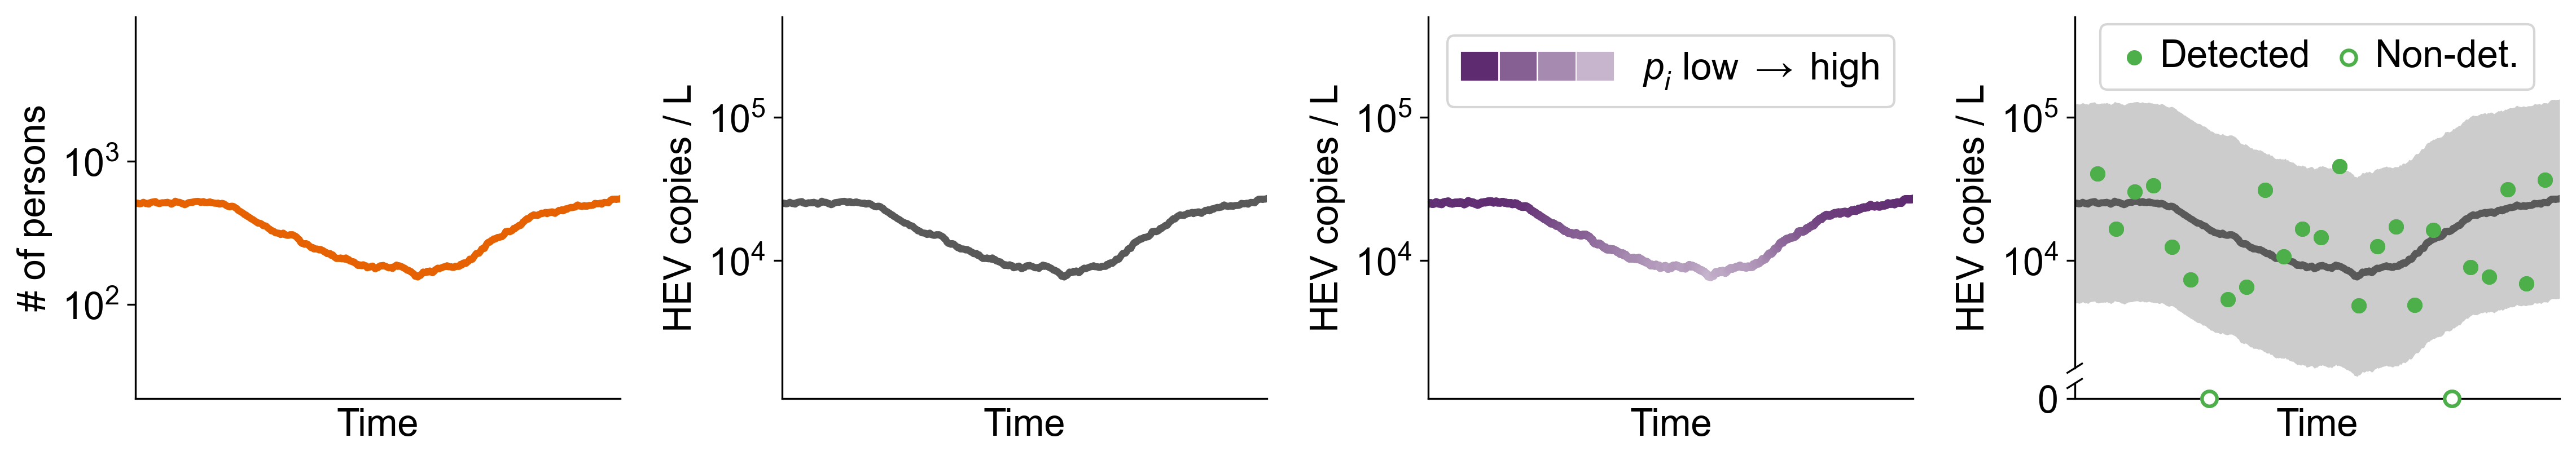

In [41]:
plt.style.use("default")
set_fontsize()

lw = 3

# colours for p_i
ramp = LinearSegmentedColormap.from_list("ramp", ["white", purple])
p_colors = [ramp(x) for x in (1.0, 0.75, 0.55, 0.35)]
p_cmap = LinearSegmentedColormap.from_list("p_low_high", p_colors)

# common log range, set by panel 4
y_lo = min(lo.min(), Cm[detected].min()) * 0.7
y_data_hi = max(hi.max(), Cm.max()) * 1.5
y_zero = y_lo
y_hi = y_data_hi * 2.5

def decades(a, b):
    return 10.0 ** np.arange(np.ceil(np.log10(a)), np.floor(np.log10(b)) + 1)

scales = [N / s, 1, 1, 1]


fig, axes = plt.subplots(1, 4, figsize=(15.5, 3), dpi=300)

ylabels = ["# of persons", "HEV copies / L", "HEV copies / L", "HEV copies / L"]

for ax, k, yl in zip(axes, scales, ylabels):
    ax.set_yscale("log")
    ax.set_ylim(y_zero * k, y_hi * k)
    ax.set_yticks(decades(y_lo * k, y_data_hi * k))
    ax.set_xlim(days[0], days[-1])
    ax.yaxis.set_minor_locator(NullLocator())
    ax.tick_params(axis="x", bottom=False, labelbottom=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("Time")
    ax.set_ylabel(yl)

# (1) shedders n_i(t)
axes[0].plot(days, n, color=orange, lw=lw)

# (2) noise-free concentration C_i(t)
axes[1].plot(days, C, color=darkgrey, lw=lw)

# (3) C_i(t) coloured by non-detection probability p_i(t)
pts = np.column_stack([days, C])
lc = LineCollection(np.stack([pts[:-1], pts[1:]], axis=1), cmap=p_cmap, norm=Normalize(p.min(), p.max()), lw=lw + 0.5, capstyle="round", joinstyle = "round")
lc.set_array(0.5 * (p[:-1] + p[1:]))
axes[2].add_collection(lc)
axes[2].legend([tuple(Patch(color=c) for c in p_colors)], [r"$p_i$ low $\rightarrow$ high"],
               handler_map={tuple: HandlerTuple(ndivide=None, pad=0.1)}, handlelength=4, loc="upper center")

# (4) measurements C_i^m(t)
ts = days[sample_idx]
show = np.ones(len(ts), dtype=bool)
show[0] = False

axes[3].fill_between(days, lo, hi, color=lightgrey, lw=0)
axes[3].plot(days, C, color=darkgrey, lw=lw)
axes[3].scatter(ts[detected & show], Cm[detected & show], color=lightgreen, s=30, zorder=3)
axes[3].scatter(ts[~detected & show], np.full((~detected & show).sum(), y_zero), facecolor="white",
                edgecolor=lightgreen, lw=1.5, s=40, zorder=4, clip_on=False)

decades = 10.0 ** np.arange(np.ceil(np.log10(y_lo)), np.floor(np.log10(y_data_hi)) + 1)
axes[3].set_yticks([y_zero, *decades], labels=["0", *[rf"$10^{{{int(np.log10(d))}}}$" for d in decades]])

frac = lambda y: np.log(y / y_zero) / np.log(y_hi / y_zero)
unfrac = lambda f: y_zero * (y_hi / y_zero) ** f
yb, gap = 0.06, 0.02

spine = axes[3].spines["left"]
spine.set_bounds(unfrac(yb + gap), y_hi) 
kw = dict(transform=axes[3].transAxes, color=spine.get_edgecolor(), lw=spine.get_linewidth(), clip_on=False)
ax.plot([0, 0], [0, yb - gap], **kw)
for y0 in (yb - gap, yb + gap):
    ax.plot([-0.015, 0.015], [y0 - 0.012, y0 + 0.012], **kw)
axes[3].scatter(ts[detected & show], Cm[detected & show], color=lightgreen, s=30, zorder=3, label="Detected")
axes[3].scatter(ts[~detected & show], np.full((~detected & show).sum(), y_zero), facecolor="white",
                edgecolor=lightgreen, lw=1.5, s=40, zorder=4, clip_on=False, label="Non-det.")
axes[3].legend(ncol=2, loc="upper center", handletextpad=0.2, columnspacing=0.5, borderaxespad=0.2, handlelength=1)

plt.tight_layout()
plt.savefig(f"{plot_path}/comic_strip.png", dpi=300)

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
to_inches = fig.dpi_scale_trans.inverted()
pad = 0.05

for i, ax in enumerate(axes, start=1):
    bb = ax.get_tightbbox(renderer).transformed(to_inches)
    crop = Bbox.from_extents(bb.x0 - pad, 0, bb.x1 + pad, fig.get_figheight())
    fig.savefig(f"{plot_path}/comic_strip_{i}.png", dpi=300, bbox_inches=crop)

plt.show()